**Disclaimer**: this notebook's compatibility with StatsBomb event data 4.0.0 was last checked on December 30th, 2023.

In [1]:
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option('display.max_columns', None)
warnings.simplefilter(action='ignore', category=pd.errors.PerformanceWarning)
warnings.filterwarnings(action="ignore", message="credentials were not supplied. open data access only")
warnings.filterwarnings(action="ignore", category=FutureWarning, module='socceraction.data.statsbomb.loader')
import tqdm

In [2]:
%load_ext autoreload
%autoreload 2
from socceraction.data.statsbomb import StatsBombLoader
import socceraction.spadl as spadl

## Set up the StatsBombLoader

In [3]:
# Use this if you want to use the free public statsbomb data
# or provide credentials to access the API
API = StatsBombLoader(getter="remote", creds={"user": None, "passwd": None})

In [4]:
# View all available competitions
competitions = API.competitions()
set(competitions.competition_name)

{'1. Bundesliga',
 'African Cup of Nations',
 'Champions League',
 'Copa America',
 'Copa del Rey',
 "FA Women's Super League",
 'FIFA U20 World Cup',
 'FIFA World Cup',
 'Indian Super league',
 'La Liga',
 'Liga Profesional',
 'Ligue 1',
 'Major League Soccer',
 'NWSL',
 'North American League',
 'Premier League',
 'Serie A',
 'UEFA Euro',
 'UEFA Europa League',
 "UEFA Women's Euro",
 "Women's World Cup"}

In [5]:
# Fifa world cup
selected_competitions = competitions[
    # ((competitions.competition_name == "UEFA Women's Euro") & (competitions.season_name.isin(["2022", "2025"])))
    ((competitions.competition_name == "UEFA Euro") & (competitions.season_name.isin(["2020", "2024"])))
    |((competitions.competition_name == "Women's World Cup") & (competitions.season_name == "2019"))
    |((competitions.competition_name == "FIFA World Cup") & (competitions.season_name == "2022"))]
    

# # Messi data
# selected_competitions = competitions[competitions.competition_name == "La Liga"]

# # FA Women's Super League
# selected_competitions = competitions[competitions.competition_name == "FA Women's Super League"]

selected_competitions

,season_id,competition_id,competition_name,country_name,competition_gender,season_name
29,106,43,FIFA World Cup,International,male,2022
68,282,55,UEFA Euro,Europe,male,2024
69,43,55,UEFA Euro,Europe,male,2020
74,30,72,Women's World Cup,International,female,2019


In [6]:
# Get games from all selected competitions
games = pd.concat([
    API.games(row.competition_id, row.season_id)
    for row in selected_competitions.itertuples()
])
games[["game_id", "home_team_id", "away_team_id", "game_date", "home_score", "away_score"]]

,game_id,home_team_id,away_team_id,game_date,home_score,away_score
0,3857256,786,773,2022-12-02 21:00:00,2,3
1,3869151,779,792,2022-12-03 21:00:00,2,1
2,3857257,792,776,2022-11-30 17:00:00,1,0
3,3857258,781,786,2022-11-24 21:00:00,2,0
4,3857288,777,792,2022-11-26 12:00:00,0,1
...,...,...,...,...,...,...
47,69199,852,865,2019-06-27 21:00:00,0,3
48,69258,865,1214,2019-07-02 21:00:00,1,2
49,69284,851,858,2019-07-03 21:00:00,1,0
50,69205,855,851,2019-06-29 15:00:00,0,2


### 1.CALCULATE VARIABLE(number of team passes per minute of possession) - Wyscout

In [7]:
def compute_and_plot_pace(events, home_team_id, away_team_id, min_duration_sec=3):
    """
    events: 一场比赛的事件表
    home_team_id, away_team_id: 用于确定主客队
    """

    filtered = events[
        ~events["type_name"].isin(["Starting XI", "Half Start", "Half End"])
    ].copy()

    # duration 确保为 float
    filtered["duration"] = filtered["duration"].astype(float)

    # ----------- 计算 possession duration -----------
    possession_duration = filtered.groupby("possession")["duration"].sum()

    # ----------- 筛掉 duration < min_duration_sec 的 possession -----------
    valid_possessions = possession_duration[possession_duration >= min_duration_sec].index

    filtered = filtered[filtered["possession"].isin(valid_possessions)]

    # 确保 timestamp 转化为秒
    if not pd.api.types.is_numeric_dtype(filtered["duration"]):
        filtered["duration"] = filtered["duration"].astype(float)

    # ----------- 计算每个 possession 的时间（分钟） -----------
    possession_time = (
        filtered.groupby("possession")["duration"].sum() / 60.0  # 转分钟
    )

    # ----------- 计算每个 possession 的传球数量 -----------
    passes = filtered[filtered["type_name"] == "Pass"]
    possession_passes = passes.groupby("possession")["event_id"].count()

    # ----------- 比赛节奏 = 传球数 / 控球分钟 -----------
    pace = (possession_passes / possession_time).fillna(0)

    # ----------- 合并球队信息 -----------
    team_of_possession = filtered.groupby("possession")["possession_team_id"].first()

    pace_df = pd.DataFrame({
        "pace": pace,
        "team_id": team_of_possession
    }).reset_index()

    # ----------- 分主客队 -----------
    home_pace = pace_df[pace_df["team_id"] == home_team_id]
    away_pace = pace_df[pace_df["team_id"] == away_team_id]

    # ----------- 可视化-----------
    # plt.figure(figsize=(14, 5))
    # plt.plot(home_pace["possession"], home_pace["pace"], marker="o", color="red", label="Home Team")
    # plt.plot(away_pace["possession"], away_pace["pace"], marker="o", color="blue", label="Away Team")

    # plt.xlabel("Possession ID")
    # plt.ylabel("Passes per Minute of Possession")
    # plt.title("Match Tempo: Passes per Minute of Possession")
    # plt.legend()
    # plt.grid(True)
    # plt.tight_layout()
    # plt.show()

    return pace_df


### 2.calculate the amount of time a player takes to play a pass after gaining control of the - (Bransen & Davis, 2025)

In [8]:
def plot_ball_action_speed(events, home_team_id, away_team_id):
    """
    按照 Bransen & Davis 方法计算传球速度
    PoP(ai) = Tai - Tai-1
    Tai: 当前球员传球时间（球离脚）
    Tai-1: 上一个队友传球时间（球离脚）
    """
    df = events.copy().reset_index(drop=True)

    # 确保时间戳格式正确
    if not pd.api.types.is_timedelta64_dtype(df["timestamp"]):
        df["timestamp"] = pd.to_timedelta(df["timestamp"])

    results = []

    # 1. 筛选所有传球事件
    pass_events = df[df["type_name"] == "Pass"].copy()

    for idx, current_pass in pass_events.iterrows():
        current_player_id = current_pass["player_id"]
        current_team_id = current_pass["team_id"]
        current_possession = current_pass["possession"]
        current_time = current_pass["timestamp"]  # Tai

        # 2. 往前找上一个**同队队友**的传球事件
        previous_events = df[
            (df.index < idx) & 
            (df["possession"] == current_possession) 
        ]
        
        if len(previous_events) == 0:
            continue

        # 情况1：队友的传球
        teammate_passes = previous_events[
            (previous_events["type_name"] == "Pass") &
            (previous_events["team_id"] == current_team_id) &
            (previous_events["player_id"] != current_player_id)
        ]

        # 情况2：当前球员自己的拦截
        player_interceptions = previous_events[
            (previous_events["type_name"] == "Interception") &
            (previous_events["player_id"] == current_player_id)
        ]

        # 合并两种情况，取最近的一个
        valid_previous = pd.concat([teammate_passes, player_interceptions])
        
        if len(valid_previous) > 0:
            previous_action = valid_previous.iloc[-1]  # 取最近的一个
            previous_time = previous_action["timestamp"]  # Tai-1

            # 计算 PoP = Tai - Tai-1
            delta = (current_time - previous_time).total_seconds()

            # 过滤异常值（合理范围：0-30秒）
            if 0 <= delta <= 30:
                results.append({
                    "player_id": current_player_id,
                    "team_id": current_team_id,
                    "possession": current_possession,
                    "previous_action": previous_action["type_name"],
                    "previous_time": previous_time,
                    "current_time": current_time,
                    "time_to_pass": delta,
                    "match_time_min": current_pass["minute"] + current_pass["second"] / 60
                })
    action_speed_df = pd.DataFrame(results)

    # if len(action_speed_df) > 0:
    #     print(f"平均 PoP: {action_speed_df['time_to_pass'].mean():.2f} 秒")
    #     print(f"中位数 PoP: {action_speed_df['time_to_pass'].median():.2f} 秒")
    #     print(f"\n前一个动作类型分布：")
    #     print(action_speed_df['previous_action'].value_counts())

    # # 可视化（可选）
    # plt.figure(figsize=(14,5))

    # # 主队
    # home_df = action_speed_df[action_speed_df["team_id"] == home_team_id]
    # plt.scatter(home_df["match_time_min"], home_df["time_to_pass"], 
    #             color="red", label="Home Team", alpha=0.6)

    # # 客队
    # away_df = action_speed_df[action_speed_df["team_id"] == away_team_id]
    # plt.scatter(away_df["match_time_min"], away_df["time_to_pass"], 
    #             color="blue", label="Away Team", alpha=0.6)

    # plt.xlabel("Match Time (min)")
    # plt.ylabel("Time to Pass (s)")
    # plt.title("Time between Teammate Passes (Bransen & Davis Method)")
    # plt.legend()
    # plt.grid(True)
    # plt.tight_layout()
    # plt.show()

    return action_speed_df

### 3.calculate meters per second per touch - Hamilton (2013) 

In [9]:
def compute_possession_tempo(events, home_team_id, away_team_id):
    """
    计算每次控球的平均球速：p_i = dist / (k * t)
    - dist: 球移动总距离 (meters)
    - k: 触球次数
    - t: 控球持续时间 (seconds)
    
    改进：
    - Pass/Shot/Carry: 使用 end_location 计算实际传球/射门/带球距离
    - 其他事件: 使用相邻事件位置差计算距离
    """
    df = events.copy()

    # 只保留触球的事件
    touch_types = [
        "Pass", "Carry", "Clearance", "Dribble", "Shot", 
        "Goal Keeper", "Interception"
    ]
    df = df[df["type_name"].isin(touch_types)]

    # 转换location列为X,Y
    df["x"] = df["location"].apply(lambda loc: loc[0] if isinstance(loc, list) else np.nan)
    df["y"] = df["location"].apply(lambda loc: loc[1] if isinstance(loc, list) else np.nan)

    # 删除缺失坐标
    df = df.dropna(subset=["x", "y"])

    # 翻转客队进攻方向
    df.loc[df["team_id"] == away_team_id, "x"] = 120 - df.loc[df["team_id"] == away_team_id, "x"]
    df.loc[df["team_id"] == away_team_id, "y"] = 80 - df.loc[df["team_id"] == away_team_id, "y"]

    # 提取 end_location 用于 Pass/Shot/Carry
    def _extract_end_location(row):
        """从 extra 字典中提取 end_location"""
        if not isinstance(row['extra'], dict):
            return None
        
        # 检查是否有 pass/shot/carry 信息
        if 'pass' in row['extra'] and 'end_location' in row['extra']['pass']:
            end_loc = row['extra']['pass']['end_location']
        elif 'shot' in row['extra'] and 'end_location' in row['extra']['shot']:
            end_loc = row['extra']['shot']['end_location']
        elif 'carry' in row['extra'] and 'end_location' in row['extra']['carry']:
            end_loc = row['extra']['carry']['end_location']
        else:
            return None
        
        # 只取 x, y 坐标（忽略 z 坐标）
        if isinstance(end_loc, list) and len(end_loc) >= 2:
            return [end_loc[0], end_loc[1]]
        return None
    
    df['end_location'] = df.apply(_extract_end_location, axis=1)
    
    # 提取 end_x, end_y（需要翻转客队坐标）
    df['end_x'] = df['end_location'].apply(lambda loc: loc[0] if loc is not None else np.nan)
    df['end_y'] = df['end_location'].apply(lambda loc: loc[1] if loc is not None else np.nan)
    
    # 翻转客队的 end_location
    away_mask = df["team_id"] == away_team_id
    df.loc[away_mask & df['end_x'].notna(), 'end_x'] = 120 - df.loc[away_mask & df['end_x'].notna(), 'end_x']
    df.loc[away_mask & df['end_y'].notna(), 'end_y'] = 80 - df.loc[away_mask & df['end_y'].notna(), 'end_y']

    # 按 possession 分组计算
    tempo_list = []
    for pid, group in df.groupby("possession"):
        group = group.sort_values("index").reset_index(drop=True)  # 按事件顺序

        # 触球次数 k
        k = len(group)
        if k < 2:
            continue  # 至少两次触球才有意义

        # 控球持续时间 t (seconds)
        first_time = group["minute"].iloc[0] * 60 + group["second"].iloc[0]
        last_time = group["minute"].iloc[-1] * 60 + group["second"].iloc[-1]
        t = last_time - first_time
        
        if t <= 0:
            continue  # 时间必须大于0

        # **改进的距离计算**
        total_dist = 0.0
        
        for i in range(len(group)):
            event_type = group.loc[i, 'type_name']
            
            # 对于 Pass/Shot/Carry，使用 end_location
            if event_type in ['Pass', 'Shot', 'Carry']:
                if pd.notna(group.loc[i, 'end_x']) and pd.notna(group.loc[i, 'end_y']):
                    x_start = group.loc[i, 'x']
                    y_start = group.loc[i, 'y']
                    x_end = group.loc[i, 'end_x']
                    y_end = group.loc[i, 'end_y']
                    
                    dist = np.sqrt((x_end - x_start)**2 + (y_end - y_start)**2)
                    total_dist += dist
            
            # 对于其他事件，使用相邻事件位置差
            elif i < len(group) - 1:
                x1, y1 = group.loc[i, 'x'], group.loc[i, 'y']
                x2, y2 = group.loc[i+1, 'x'], group.loc[i+1, 'y']
                
                dist = np.sqrt((x2 - x1)**2 + (y2 - y1)**2)
                total_dist += dist

        # 计算 p_i = dist / (k * t)
        p_i = total_dist / (k * t)

        # 记录数据
        team_id = group["team_id"].iloc[0]
        match_time = group["minute"].iloc[0] + group["second"].iloc[0] / 60

        tempo_list.append({
            "possession": pid,
            "team_id": team_id,
            "total_distance": total_dist,
            "n_touches": k,
            "duration_sec": t,
            "tempo_m_per_touch_per_sec": p_i,  
            "match_time_min": match_time
        })

    tempo_df = pd.DataFrame(tempo_list)

    # 计算全场平均节奏 P
    # if len(tempo_df) > 0:
    #     P_overall = tempo_df["tempo_m_per_touch_per_sec"].mean()
    #     P_home = tempo_df[tempo_df["team_id"] == home_team_id]["tempo_m_per_touch_per_sec"].mean()
    #     P_away = tempo_df[tempo_df["team_id"] == away_team_id]["tempo_m_per_touch_per_sec"].mean()
        
    #     print(f"Overall Average Tempo P: {P_overall:.3f} m/(touch·sec)")
    #     print(f"Home Team Average Tempo: {P_home:.3f} m/(touch·sec)")
    #     print(f"Away Team Average Tempo: {P_away:.3f} m/(touch·sec)")

    # 可视化
    # plt.figure(figsize=(14,5))
    # home_df = tempo_df[tempo_df["team_id"] == home_team_id]
    # away_df = tempo_df[tempo_df["team_id"] == away_team_id]
    # plt.scatter(home_df["match_time_min"], home_df["tempo_m_per_touch_per_sec"], 
    #             color="red", label="Home Team", alpha=0.6)
    # plt.scatter(away_df["match_time_min"], away_df["tempo_m_per_touch_per_sec"], 
    #             color="blue", label="Away Team", alpha=0.6)
    # plt.xlabel("Match Time (min)")
    # plt.ylabel("Tempo: m/(touch·sec)")
    # plt.title("Possession Tempo: Distance per Touch per Second")
    # plt.legend()
    # plt.grid(True)
    # plt.tight_layout()
    # plt.show()

    return tempo_df

### 4.calculate the speed of ball movement relative to time(d/t) - Shen (2022)

In [10]:
def compute_possession_speed_mps(events, home_team_id, away_team_id):
    """
    计算每次控球内基于时间的平均球速（meters per second）
    可视化：主队红色，客队蓝色
    """

    df = events.copy()

    # 1. 筛选有效事件
    exclude_types = [
        "Starting XI", "Half Start", "Pressure", "Miscontrol",
        "Tactical Shift", "Half End", "Player Off", "Substitution",
        "Foul Won", "Dribbled Past", "Shield", "Bad Behaviour"
    ]
    df = df[~df["type_name"].isin(exclude_types)]

    # 2. location → x, y
    df["x"] = df["location"].apply(lambda loc: loc[0] if isinstance(loc, list) else np.nan)
    df["y"] = df["location"].apply(lambda loc: loc[1] if isinstance(loc, list) else np.nan)
    df = df.dropna(subset=["x", "y"])

    # 3. 统一进攻方向（客队翻转）
    df.loc[df["team_id"] == away_team_id, "x"] = 120 - df.loc[df["team_id"] == away_team_id, "x"]
    df.loc[df["team_id"] == away_team_id, "y"] = 80 - df.loc[df["team_id"] == away_team_id, "y"]

    # 4. 构建连续时间轴（分钟 & 秒）
    df["event_time_min"] = df["minute"] + df["second"] / 60

    possession_speed = []

    # 5. 按 possession 计算
    for pid, group in df.groupby("possession"):
        group = group.sort_values("index")

        if len(group) < 3:
            continue

        coords = group[["x", "y"]].values

        # 连续事件的球移动距离
        distances = np.sqrt(np.sum(np.diff(coords, axis=0) ** 2, axis=1))
        total_distance = distances.sum()  # meters

        # possession 持续时间（秒）
        start_time = group["event_time_min"].iloc[0]
        end_time = group["event_time_min"].iloc[-1]
        duration_sec = (end_time - start_time) * 60

        if duration_sec <= 0:
            continue

        avg_speed_mps = total_distance / duration_sec

        possession_speed.append({
            "possession": pid,
            "team_id": group["team_id"].iloc[0],
            "total_distance_m": total_distance,
            "duration_sec": duration_sec,
            "avg_speed_mps": avg_speed_mps,
            "match_time_min": start_time
        })

    speed_df = pd.DataFrame(possession_speed)

    # 6. 可视化
    # plt.figure(figsize=(14, 5))

    # home_df = speed_df[speed_df["team_id"] == home_team_id]
    # away_df = speed_df[speed_df["team_id"] == away_team_id]

    # plt.scatter(
    #     home_df["match_time_min"],
    #     home_df["avg_speed_mps"],
    #     label="Home Team",
    #     color="red",
    #     alpha=0.7
    # )

    # plt.scatter(
    #     away_df["match_time_min"],
    #     away_df["avg_speed_mps"],
    #     label="Away Team",
    #     color="blue",
    #     alpha=0.7
    # )

    # plt.xlabel("Match Time (min)")
    # plt.ylabel("Average Ball Speed (m/s)")
    # plt.title("Average Ball Speed per Possession")
    # plt.legend()
    # plt.grid(True)
    # plt.tight_layout()
    # plt.show()

    return speed_df

In [11]:
PACE_METHODS = {
    "passes_per_min": compute_and_plot_pace,
    "time_to_pass": plot_ball_action_speed,
    "meters_per_seconds_per_touch": compute_possession_tempo,
    "meters_per_second": compute_possession_speed_mps
}

def aggregate_match_team(df, value_col):
    return (
        df
        .groupby("team_id")[value_col]
        .mean()
        .reset_index()
        .rename(columns={value_col: "tempo"})
    )

### match × team metric

In [ ]:
h5_path = "../data/men-statsbomb.h5"
analysis_rows = []

with pd.HDFStore(h5_path, mode="r") as store:

    games_df = store["games"]

    for game_id in games_df["game_id"].unique():

        event_key = f"events/game_{game_id}"
        if event_key not in store:
            continue

        events = store[event_key]

        home_team_id = games_df.loc[
            games_df["game_id"] == game_id, "home_team_id"
        ].iloc[0]

        away_team_id = games_df.loc[
            games_df["game_id"] == game_id, "away_team_id"
        ].iloc[0]

        for method_name, method_func in PACE_METHODS.items():

            df_method = method_func(events, home_team_id, away_team_id)

            if method_name == "passes_per_min":
                value_col = "pace"
            elif method_name == "time_to_pass":
                value_col = "time_to_pass"
            elif method_name == "meters_per_seconds_per_touch":
                value_col = "tempo_m_per_touch_per_sec"
            elif method_name == "meters_per_second":
                value_col = "avg_speed_mps"
            else:
                raise ValueError("Unknown method")

            # possession → match × team
            agg_df = aggregate_match_team(df_method, value_col)

            agg_df["game_id"] = game_id
            agg_df["method"] = method_name

            analysis_rows.append(agg_df)

final_df = pd.concat(analysis_rows, ignore_index=True)

In [ ]:
h5_path = "../data/women-statsbomb4.h5"
analysis_rows = []

with pd.HDFStore(h5_path, mode="r") as store:

    games_df = store["games"]

    for game_id in games_df["game_id"].unique():

        event_key = f"events/game_{game_id}"
        if event_key not in store:
            continue

        events = store[event_key]

        home_team_id = games_df.loc[
            games_df["game_id"] == game_id, "home_team_id"
        ].iloc[0]

        away_team_id = games_df.loc[
            games_df["game_id"] == game_id, "away_team_id"
        ].iloc[0]

        for method_name, method_func in PACE_METHODS.items():

            df_method = method_func(events, home_team_id, away_team_id)

            if method_name == "passes_per_min":
                value_col = "pace"
            elif method_name == "time_to_pass":
                value_col = "time_to_pass"
            elif method_name == "meters_per_seconds_per_touch":
                value_col = "tempo_m_per_touch_per_sec"
            elif method_name == "meters_per_second":
                value_col = "avg_speed_mps"
            else:
                raise ValueError("Unknown method")

            # possession → match × team
            agg_df = aggregate_match_team(df_method, value_col)

            agg_df["game_id"] = game_id
            agg_df["method"] = method_name

            analysis_rows.append(agg_df)

# merge women data to final_df
final_df = pd.concat([final_df, pd.concat(analysis_rows, ignore_index=True)], ignore_index=True)

In [14]:
season_map = pd.DataFrame({
    "season_id":      [43,  106, 282,  106, 30,  315, 107],
    "competition_id": [55,  43,  55,   53,  72,  53,  72],
    "year":           [2020, 2022, 2024, 2022, 2019, 2025, 2023],
    "gender":         ["Men", "Men", "Men", "Women", "Women", "Women", "Women"],
    "tournament":     ["EURO2020", "WC2022", "EURO2024", "WEURO2022", "WWC2019", "WEURO2025", "WWC2023"]
})

In [15]:
def _load_meta(path):
    with pd.HDFStore(path, mode="r") as store:
        return store["teams"], store["games"]

teams_m, games_m = _load_meta("../data/men-statsbomb.h5")
teams_w, games_w = _load_meta("../data/women-statsbomb4.h5")

teams = pd.concat([teams_m, teams_w]).drop_duplicates(subset="team_id")
games = pd.concat([games_m, games_w]).drop_duplicates(subset="game_id")

final_df = final_df.merge(
    teams[["team_id", "team_name"]],
    on="team_id",
    how="left"
)

final_df = final_df.merge(
    games[["game_id", "competition_id", "season_id"]],
    on="game_id",
    how="left"
)

final_df = final_df.merge(
    season_map,
    on=["season_id", "competition_id"],
    how="left"
)

In [16]:
final_df["year"].unique()

array([2022, 2024, 2020, 2025, 2023, 2019])

In [17]:
final_df

,team_id,tempo,game_id,method,team_name,competition_id,season_id,year,gender,tournament
0,773,20.321227,3857256,passes_per_min,Switzerland,43,106,2022,Men,WC2022
1,786,19.901873,3857256,passes_per_min,Serbia,43,106,2022,Men,WC2022
2,773,3.562097,3857256,time_to_pass,Switzerland,43,106,2022,Men,WC2022
3,786,3.500427,3857256,time_to_pass,Serbia,43,106,2022,Men,WC2022
4,773,3.363050,3857256,meters_per_seconds_per_touch,Switzerland,43,106,2022,Men,WC2022
...,...,...,...,...,...,...,...,...,...,...
2747,1214,3.816006,69161,time_to_pass,United States Women's,72,30,2019,Women,WWC2019
2748,863,3.549797,69161,meters_per_seconds_per_touch,Spain Women's,72,30,2019,Women,WWC2019
2749,1214,2.590957,69161,meters_per_seconds_per_touch,United States Women's,72,30,2019,Women,WWC2019
2750,863,10.720331,69161,meters_per_second,Spain Women's,72,30,2019,Women,WWC2019


In [ ]:
# print("\n\n不同的method类型:")
# print(df_lmm['method'].unique())
# print("\n不同的球队:")
# print(df_lmm['team_name'].unique())
# print("\n不同的赛季:")
# print(df_lmm['season_id'].unique())

# 按球队、赛季和指标类型进行描述性统计
print("\n\n=== 按球队和赛季的描述性统计 ===\n")

# 为每个指标类型创建单独的统计
for method in final_df['method'].unique():
    print(f"\n{'='*60}")
    print(f"指标: {method}")
    print(f"{'='*60}")
    
    method_data = final_df[final_df['method'] == method]
    
    stats = method_data.groupby(['team_name', 'season_id'])['tempo'].agg([
        ('count', 'count'),
        ('mean', 'mean'),
        ('std', 'std'),
        ('min', 'min'),
        ('25%', lambda x: x.quantile(0.25)),
        ('median', 'median'),
        ('75%', lambda x: x.quantile(0.75)),
        ('max', 'max')
    ]).round(4)
    
    print(stats)

print("\n\n=== 综合汇总表 ===\n")
summary = final_df.groupby(['team_name', 'season_id', 'method'])['tempo'].agg([
    'count', 'mean', 'std', 'min', 'max'
]).round(4)
print(summary)

### New -- "WC2022"vs"WEURO2022"

In [19]:
import statsmodels.formula.api as smf

In [ ]:
lmm = final_df.copy()
lmm['year_c'] = lmm['year'] - 2019
# ── flirter WC2022 & WEURO2022 
lmm_sub = lmm[lmm["tournament"].isin(["WC2022", "WEURO2022"])].copy()
lmm_sub = lmm_sub.dropna(subset=["tempo", "team_id", "game_id"])
lmm_sub["tournament"] = pd.Categorical(
    lmm_sub["tournament"], categories=["WC2022", "WEURO2022"]
)

print("observations (tournament × method):")
print(lmm_sub.groupby(["tournament", "method"]).size().unstack(fill_value=0))

observations (tournament × method):
method      meters_per_second  meters_per_seconds_per_touch  passes_per_min  \
tournament                                                                    
WC2022                    128                           128             128   
WEURO2022                  62                            62              62   

method      time_to_pass  
tournament                
WC2022               128  
WEURO2022             62  


/var/folders/5q/n41m5cm5731c6p86wvjy05dc0000gp/T/ipykernel_32591/1238281616.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(lmm_sub.groupby(["tournament", "method"]).size().unstack(fill_value=0))


In [28]:
# ── MixedLM ────
model_cmp = smf.mixedlm(
    "tempo ~ C(tournament, Treatment(\'WC2022\')) + method",
    data=lmm_sub,
    groups=lmm_sub["team_id"],
    vc_formula={"game": "0 + C(game_id)"}
)
result_cmp = model_cmp.fit(reml=True)
print(result_cmp.summary())

                           Mixed Linear Model Regression Results
Model:                        MixedLM             Dependent Variable:             tempo    
No. Observations:             760                 Method:                         REML     
No. Groups:                   48                  Scale:                          0.7342   
Min. group size:              12                  Log-Likelihood:                 -992.3610
Max. group size:              28                  Converged:                      Yes      
Mean group size:              15.8                                                         
-------------------------------------------------------------------------------------------
                                                Coef.  Std.Err.    z    P>|z| [0.025 0.975]
-------------------------------------------------------------------------------------------
Intercept                                        9.622    0.069 139.438 0.000  9.487  9.758
C(tournament, T


WEURO2022 vs WC2022:  β=-0.1495  SE=0.0756  p=0.0479 *
95% CI: [-0.2977, -0.0014]


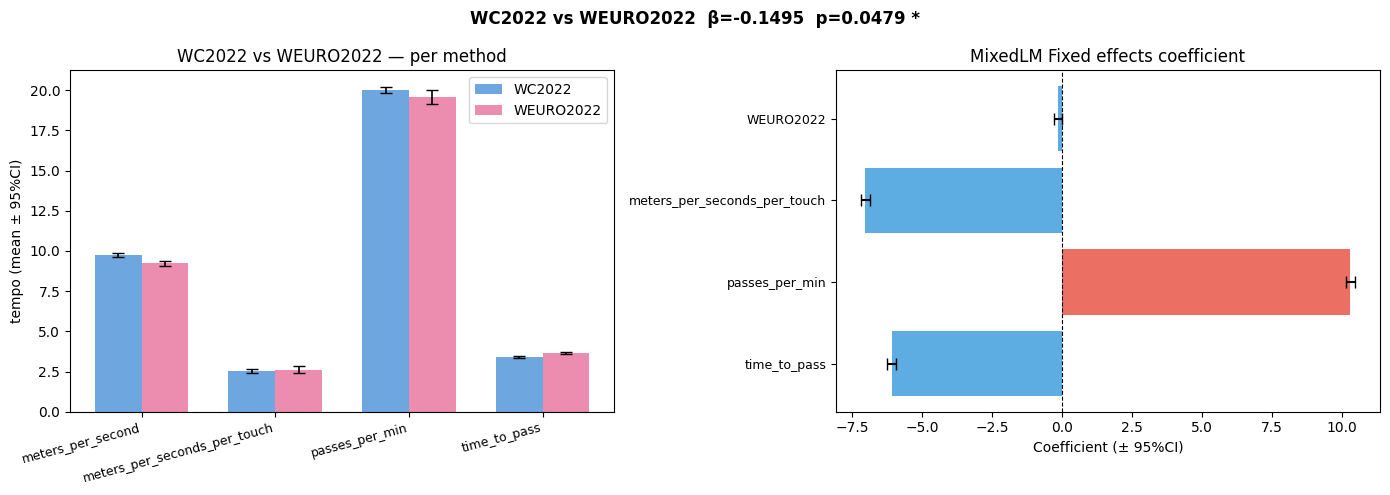

In [ ]:
WEURO_KEY = "C(tournament, Treatment(\'WC2022\'))[T.WEURO2022]"
b   = result_cmp.params[WEURO_KEY]
se  = result_cmp.bse[WEURO_KEY]
p   = result_cmp.pvalues[WEURO_KEY]
ci  = (b - 1.96 * se, b + 1.96 * se)
sig = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"
print(f"\nWEURO2022 vs WC2022:  β={b:+.4f}  SE={se:.4f}  p={p:.4f} {sig}")
print(f"95% CI: [{ci[0]:.4f}, {ci[1]:.4f}]")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# left:mean ± 95%CI
methods_list = sorted(lmm_sub["method"].unique())
x = np.arange(len(methods_list))
width = 0.35
pal = {"WC2022": "#4a90d9", "WEURO2022": "#e8709a"}

for ti, tourn in enumerate(["WC2022", "WEURO2022"]):
    grp = lmm_sub[lmm_sub["tournament"] == tourn]
    means = [grp[grp["method"] == m]["tempo"].mean() for m in methods_list]
    cis   = [grp[grp["method"] == m]["tempo"].sem() * 1.96 for m in methods_list]
    axes[0].bar(x + (ti - 0.5) * width, means, width,
                label=tourn, color=pal[tourn], alpha=0.8)
    axes[0].errorbar(x + (ti - 0.5) * width, means, yerr=cis,
                     fmt="none", color="black", capsize=4, lw=1.2)

axes[0].set_xticks(x)
axes[0].set_xticklabels(methods_list, rotation=15, ha="right", fontsize=9)
axes[0].axhline(0, color="gray", lw=0.8, ls="--")
axes[0].set(ylabel="tempo (mean ± 95%CI)",
            title="WC2022 vs WEURO2022 — per method")
axes[0].legend()

drop_keys = {"Intercept", "Group Var", "game Var"}
fe_idx  = [k for k in result_cmp.params.index if k not in drop_keys]
fe_b    = result_cmp.params[fe_idx]
fe_se   = result_cmp.bse[fe_idx]

labels = [k.split("[T.")[-1].rstrip("]") if "[T." in k else k for k in fe_idx]

y_pos = np.arange(len(fe_b))
colors_fe = ["#e74c3c" if v > 0 else "#3498db" for v in fe_b.values]
axes[1].barh(y_pos, fe_b.values, xerr=1.96 * fe_se.values,
             color=colors_fe, alpha=0.8, capsize=4)
axes[1].axvline(0, color="black", lw=0.8, ls="--")
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(labels, fontsize=9)
axes[1].set(xlabel="Coefficient (± 95%CI)", title="MixedLM Fixed effects coefficient")
axes[1].invert_yaxis()

plt.suptitle(f"WC2022 vs WEURO2022  β={b:+.4f}  p={p:.4f} {sig}", fontweight="bold")
plt.tight_layout()
plt.show()

### all competitions in a model

In [31]:
# ── MixedLM ────
model_interaction = smf.mixedlm(
    "tempo ~ gender * year_c + method", 
    data=lmm,
    groups=lmm["team_id"],
    vc_formula={
        "game": "0 + C(game_id)",
        "tournament": "0 + C(tournament)"
    }
)
result_interaction = model_interaction.fit(reml=True)
print(result_interaction.summary())

/opt/miniconda3/envs/pace/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/miniconda3/envs/pace/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(


                       Mixed Linear Model Regression Results
Model:                     MixedLM          Dependent Variable:          tempo     
No. Observations:          2752             Method:                      REML      
No. Groups:                91               Scale:                       0.7425    
Min. group size:           12               Log-Likelihood:              -3675.0323
Max. group size:           104              Converged:                   Yes       
Mean group size:           30.2                                                    
-----------------------------------------------------------------------------------
                                       Coef.  Std.Err.    z     P>|z| [0.025 0.975]
-----------------------------------------------------------------------------------
Intercept                               9.713    0.113   86.141 0.000  9.492  9.934
gender[T.Women]                        -0.282    0.138   -2.041 0.041 -0.553 -0.011
method[T.meters

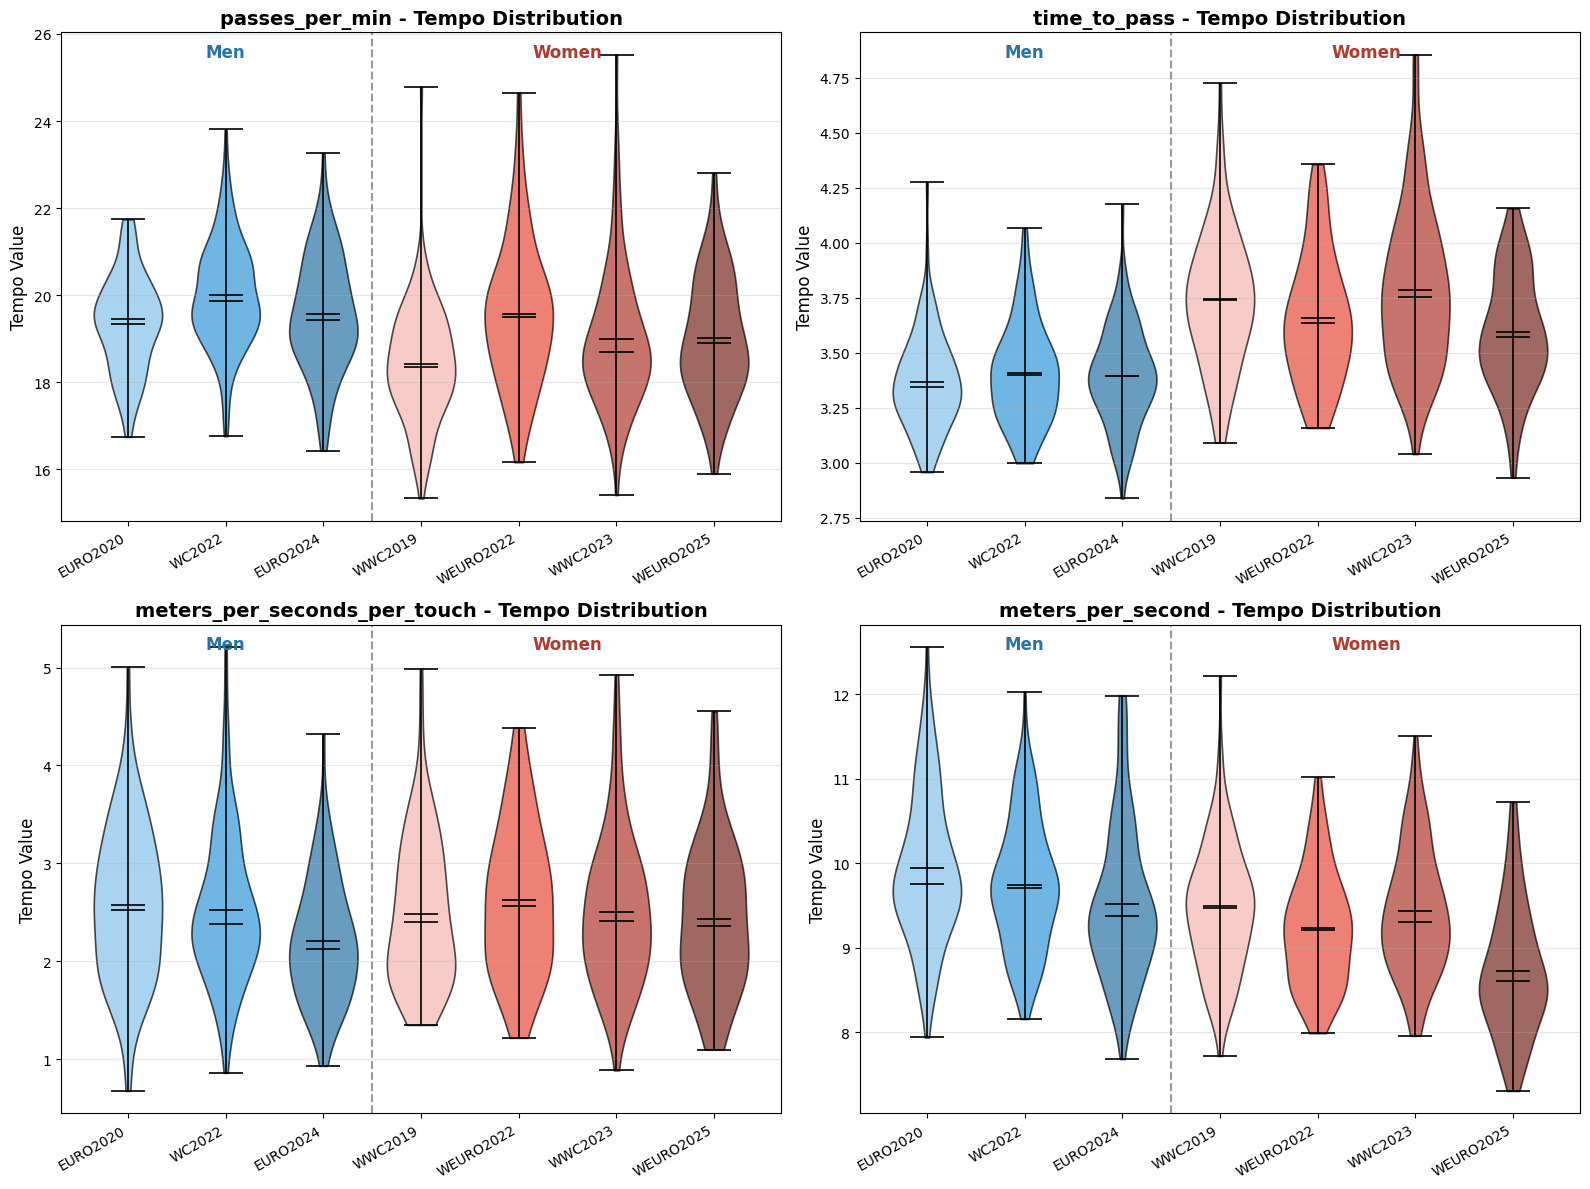

In [ ]:
tournaments_order = ["EURO2020", "WC2022", "EURO2024", "WWC2019", "WEURO2022", "WWC2023", "WEURO2025"]

tourn_colors = ["#85C1E9", "#3498DB", "#2874A6",  # men
                "#F5B7B1", "#E74C3C", "#B03A2E", "#78281F"] # women

methods = final_df['method'].unique()

fig2, axes2 = plt.subplots(2, 2, figsize=(16, 12))
axes2 = axes2.flatten()

for idx, method in enumerate(methods):
    ax = axes2[idx]
    method_data = final_df[final_df['method'] == method]
    
    plot_data = [method_data[method_data['tournament'] == tourn]['tempo'].dropna() for tourn in tournaments_order]
    
    parts = ax.violinplot(
        plot_data,
        positions=range(len(tournaments_order)),
        widths=0.7,
        showmeans=True,
        showmedians=True
    )
    
    for i, pc in enumerate(parts['bodies']):
        pc.set_facecolor(tourn_colors[i])
        pc.set_alpha(0.7)
        pc.set_edgecolor('black')
        pc.set_linewidth(1.2)
        
    for partname in ('cbars', 'cmins', 'cmaxes', 'cmeans', 'cmedians'):
        vp = parts[partname]
        vp.set_edgecolor('black')
        vp.set_linewidth(1.2)
    
    ax.set_title(f'{method} - Tempo Distribution', fontsize=14, fontweight='bold')
    ax.set_ylabel('Tempo Value', fontsize=12)
    ax.set_xticks(range(len(tournaments_order)))

    ax.set_xticklabels(tournaments_order, fontsize=10, rotation=30, ha='right') 
    ax.grid(True, alpha=0.3, axis='y')
    
    ax.axvline(x=2.5, color='gray', linestyle='--', linewidth=1.5, alpha=0.8)
    
    y_min, y_max = ax.get_ylim()
    y_text = y_max - (y_max - y_min) * 0.05
    
    ax.text(1.0, y_text, 'Men', ha='center', fontsize=12, fontweight='bold', color='#2874A6')
    ax.text(4.5, y_text, 'Women', ha='center', fontsize=12, fontweight='bold', color='#B03A2E')

plt.tight_layout()
plt.savefig('tempo_tournament_violin.png', dpi=300, bbox_inches='tight')
plt.show()
